# Identifying outliers

Outliers are atypical values—data points that fall well outside the norm. In statistics, this refers to a data point that deviates significantly from the standard distribution of the dataset.

In [2]:
import pandas as pd
import numpy as np

In [3]:
no_empty_data = pd.read_json('/content/drive/MyDrive/Collab Notebooks - Alura/part_5_pandas_data_cleaning/resources/telecon_normalized_data_v3.json')

df_without_null = pd.read_json('/content/drive/MyDrive/Collab Notebooks - Alura/part_5_pandas_data_cleaning/resources/subset_without_null.json')

Below, I have provided a boxplot, which we will use shortly to determine whether or not our data contains potential outliers.

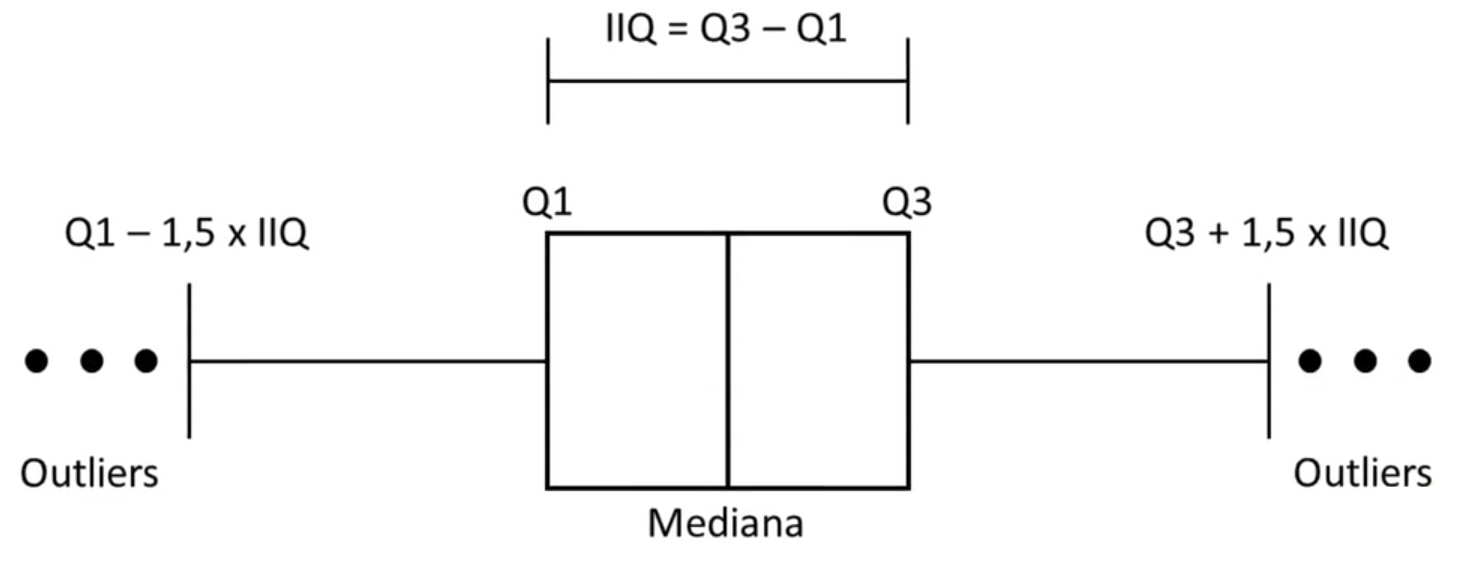

As the name suggests, a *boxplot*—literally a "box plot"—is represented by a rectangle. Inside this box, there is a line known as the median, which divides the data in half; 50% of the data points lie to the left of this line, and the other 50% lie to the right.
***
At the left and right ends of the box are Q1 and Q3—the quartiles—which divide the dataset into four equal parts, each containing 25% of the data. Thus, the range up to Q1 encompasses the first 25% of the data (the quarter with the lowest values).
***
Beyond Q1, we find the remaining 75% of the data. Here, Q2 represents the median, while Q3 marks the point up to which 75% of the data is contained; the final 25% of the data—consisting of the highest values ​​in the set—lies beyond Q3.
***
Associated with the box (and specifically Q1 and Q3) is the "IQR" (Interquartile Range), calculated as Q3 minus Q1.
***
Extending from the left and right sides of the box are "whiskers." The end of the left whisker is defined by the formula "Q1 - 1.5 × IQR," which establishes the lower limit. The end of the right whisker is defined by "Q3 + 1.5 × IQR," which establishes the upper limit. Any values ​​falling below the lower limit or above the upper limit are considered *potential outliers* which is precisely what we are looking for.

### Working with outliers

In [4]:
df_without_null.describe()

,cliente.idoso,cliente.tempo_servico,conta.cobranca.mensal,conta.cobranca.Total
count,7006.000000,7006.000000,7006.000000,7006.000000
mean,0.162004,33.286183,64.720361,2317.743862
std,0.368481,35.311206,30.084664,2876.919022
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.450000,402.087500
50%,0.000000,29.000000,70.300000,1392.925000
75%,0.000000,56.000000,89.850000,3783.600000
max,1.000000,1080.000000,118.750000,112212.000000


In [5]:
1080/12

90.0

`cliente.tempo_servico` represents the length of time, in months, that someone has subscribed to the telephone service. We observe a maximum value of 1080 months that is, 90 years.

It is questionable whether someone could maintain the same subscription for 90 years,
this might be an indication of outliers.

In [6]:
import seaborn as sns

<Axes: xlabel='cliente.tempo_servico'>

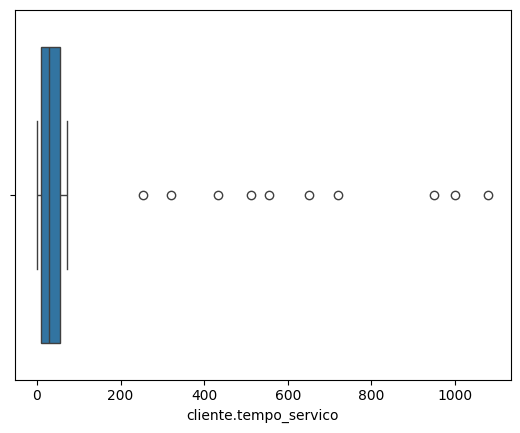

In [7]:
sns.boxplot(x=df_without_null['cliente.tempo_servico'])

In [8]:
Q1 = df_without_null['cliente.tempo_servico'].quantile(.25)
print(f'Q1: {Q1}')

Q3 = df_without_null['cliente.tempo_servico'].quantile(.75)
print(f'Q3: {Q3}')

IQR = Q3 - Q1
print(f'IQR: {IQR}')

Q1: 9.0
Q3: 56.0
IQR: 47.0


In [9]:
lower_limit = Q1 -1.5 * IQR
print(f'Lower limit: {lower_limit}')

upper_limit = Q3 + 1.5 * IQR
print(f'Upper limit: {upper_limit}')

Lower limit: -61.5
Upper limit: 126.5


In [10]:
outliers_index = (df_without_null['cliente.tempo_servico'] < lower_limit) | (df_without_null['cliente.tempo_servico'] > upper_limit)
outliers_index

,cliente.tempo_servico
0,False
1,False
2,False
3,False
4,False
...,...
7001,False
7002,False
7003,False
7004,False


In [11]:
df_without_null[outliers_index]['cliente.tempo_servico']

,cliente.tempo_servico
1945,1080
1946,1000
1952,950
1956,254
1958,321
1963,650
1966,721
1970,555
1973,433
1974,512


Now we have identified our pontential *outliers*. What can we do with them?

If we feed the data into a machine learning model in its current state—which is the intended approach when working with this dataset—the model will learn incorrect patterns. For instance, we have already identified a 90-year contract and another lasting just under 90 years; these make no sense and represent entirely erroneous patterns within the data.

If a machine learning model is built using this data, it will learn these flawed patterns and, consequently, produce inaccurate predictions. This is why we must process and clean the data.

### Replacing values ​​for outliers

- The first thing we will try to do is replace these outliers with correct data, so as not to lose any more data samples.

In [12]:
df_without_outliers = df_without_null.copy()

In [13]:
df_without_null.to_json('subset_without_null_v2.json')

In [14]:
df_without_outliers[outliers_index]['cliente.tempo_servico']

,cliente.tempo_servico
1945,1080
1946,1000
1952,950
1956,254
1958,321
1963,650
1966,721
1970,555
1973,433
1974,512


What we need to do is take advantage of the relationship involving the `"cliente.tempo_servico"` column.

This column is related to two others that we are already quite familiar with: `"conta.cobranca.mensal"` and `"conta.cobranca.Total"` The relationship is such that, if we divide the value in the "Total" column by the value in the "mensal" (monthly) column, we obtain the service duration ("tempo_servico").

In [15]:
df_without_outliers.loc[outliers_index, 'cliente.tempo_servico'] = np.ceil(
    df_without_outliers.loc[outliers_index, 'conta.cobranca.Total'] /
    df_without_outliers.loc[outliers_index, 'conta.cobranca.mensal']
)

<Axes: xlabel='cliente.tempo_servico'>

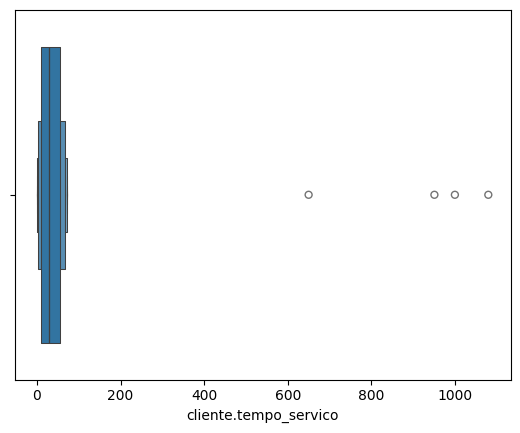

In [16]:
sns.boxenplot(x=df_without_outliers['cliente.tempo_servico'])

In [17]:
df_without_outliers[outliers_index]['cliente.tempo_servico']

,cliente.tempo_servico
1945,1080
1946,1000
1952,951
1956,2
1958,43
1963,650
1966,44
1970,7
1973,4
1974,1


We observed that some values ​​were replaced, resulting in the following: (2, 43, 44, 7, 4, and 1.) However, some values ​​remained: (1080, 1000, 951, and 650). It should be noted that the value "1952" was previously "950.0", however, because we performed a division and rounded up, the decimal component caused the value to increase to "951.0".
***
We have four values ​​that remain outliers, and we need to analyze why this happened.
***

In [18]:
df_without_outliers[outliers_index][['cliente.tempo_servico', \
                                     'conta.cobranca.mensal', 'conta.cobranca.Total']]

,cliente.tempo_servico,conta.cobranca.mensal,conta.cobranca.Total
1945,1080,103.90,112212.00
1946,1000,45.90,45900.00
1952,951,84.10,79895.00
1956,2,46.05,80.35
1958,43,99.80,4259.30
1963,650,73.00,47450.00
1966,44,89.55,3856.75
1970,7,19.15,124.40
1973,4,89.20,346.20
1974,1,19.55,19.55


We observe that some samples remain outliers because the value in "conta.cobranca.Total" is also an outlier. When an outlier is divided by a normal value, the result remains an outlier.

Consequently, we cannot reliably infer the value for "cliente.tempo_servico" in these samples that persist as outliers. Upon further investigation, we can remove these specific samples to prevent them from incorrectly influencing the machine learning model.

### Removing outliers

In [19]:
df_without_outliers[outliers_index]['cliente.tempo_servico']

,cliente.tempo_servico
1945,1080
1946,1000
1952,951
1956,2
1958,43
1963,650
1966,44
1970,7
1973,4
1974,1


Our `outliers_index` filter also contains values ​​that are no longer outliers: (2, 43, 44, 7, 4, and 1). Therefore, we need to recreate this filter, as it is now compromised.

In [20]:
Q1 = df_without_outliers['cliente.tempo_servico'].quantile(.25)
print(f'Q1: {Q1}')

Q3 = df_without_outliers['cliente.tempo_servico'].quantile(.75)
print(f'Q3: {Q3}')

IQR = Q3 - Q1
print(f'IQR: {IQR}')

Q1: 9.0
Q3: 55.0
IQR: 46.0


In [21]:
lower_limit = Q1 -1.5 * IQR
print(f'Lower limit: {lower_limit}')

upper_limit = Q3 + 1.5 * IQR
print(f'Upper limit: {upper_limit}')

Lower limit: -60.0
Upper limit: 124.0


In [22]:
outliers_index = (df_without_outliers['cliente.tempo_servico'] < lower_limit) | (df_without_outliers['cliente.tempo_servico'] > upper_limit)
outliers_index

,cliente.tempo_servico
0,False
1,False
2,False
3,False
4,False
...,...
7001,False
7002,False
7003,False
7004,False


In [23]:
df_without_outliers[outliers_index]

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
1945,2830-LEWOA,nao,masculino,0,sim,sim,1080,sim,nao,fibra otica,...,sim,sim,sim,sim,sim,um ano,nao,cartao de credito (automatico),103.9,112212.0
1946,2831-EBWRN,nao,masculino,0,nao,nao,1000,sim,nao,DSL,...,nao,nao,nao,nao,nao,mes a mes,sim,cheque eletronico,45.9,45900.0
1952,2834-SPCJV,sim,masculino,0,sim,nao,951,sim,nao,fibra otica,...,nao,nao,nao,sim,nao,mes a mes,nao,cheque eletronico,84.1,79895.0
1963,2851-STERV,nao,masculino,1,nao,nao,650,sim,nao,DSL,...,nao,sim,sim,sim,sim,um ano,sim,cheque eletronico,73.0,47450.0


In [24]:
df_without_outliers = df_without_outliers[~outliers_index]
df_without_outliers

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
0,0003-MKNFE,nao,masculino,0,nao,nao,9,sim,sim,DSL,...,nao,nao,nao,nao,sim,mes a mes,nao,cheque pelo correio,59.90,542.40
1,0004-TLHLJ,sim,masculino,0,nao,nao,4,sim,nao,fibra otica,...,nao,sim,nao,nao,nao,mes a mes,sim,cheque eletronico,73.90,280.85
2,0011-IGKFF,sim,masculino,1,sim,nao,13,sim,nao,fibra otica,...,sim,sim,nao,sim,sim,mes a mes,sim,cheque eletronico,98.00,1237.85
3,0013-EXCHZ,sim,feminino,1,sim,nao,3,sim,nao,fibra otica,...,nao,nao,sim,sim,nao,mes a mes,sim,cheque pelo correio,83.90,267.40
4,0013-MHZWF,nao,feminino,0,nao,sim,9,sim,nao,DSL,...,nao,nao,sim,sim,sim,mes a mes,sim,cartao de credito (automatico),69.40,571.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7001,9987-LUTYD,nao,feminino,0,nao,nao,13,sim,nao,DSL,...,nao,nao,sim,nao,nao,um ano,nao,cheque pelo correio,55.15,742.90
7002,9992-RRAMN,sim,masculino,0,sim,nao,22,sim,sim,fibra otica,...,nao,nao,nao,nao,sim,mes a mes,sim,cheque eletronico,85.10,1873.70
7003,9992-UJOEL,nao,masculino,0,nao,nao,2,sim,nao,DSL,...,sim,nao,nao,nao,nao,mes a mes,sim,cheque pelo correio,50.30,92.75
7004,9993-LHIEB,nao,masculino,0,sim,sim,67,sim,nao,DSL,...,nao,sim,sim,nao,sim,dois anos,nao,cheque pelo correio,67.85,4627.65


<Axes: xlabel='cliente.tempo_servico'>

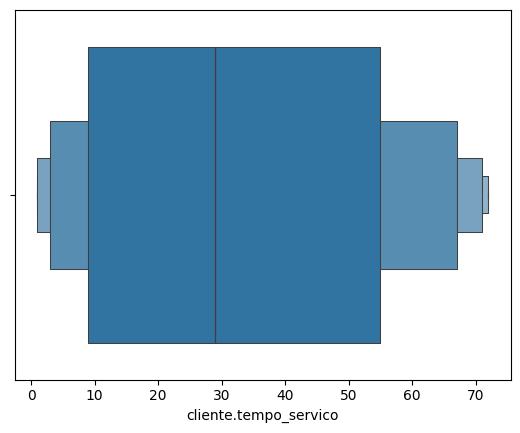

In [25]:
sns.boxenplot(x=df_without_outliers['cliente.tempo_servico'])

In [26]:
df_without_outliers.reset_index(drop=True, inplace=True)

In [27]:
df_without_outliers

,id_cliente,Churn,cliente.genero,cliente.idoso,cliente.parceiro,cliente.dependentes,cliente.tempo_servico,telefone.servico_telefone,telefone.varias_linhas,internet.servico_internet,...,internet.backup_online,internet.protecao_dispositivo,internet.suporte_tecnico,internet.tv_streaming,internet.filmes_streaming,conta.contrato,conta.faturamente_eletronico,conta.metodo_pagamento,conta.cobranca.mensal,conta.cobranca.Total
0,0003-MKNFE,nao,masculino,0,nao,nao,9,sim,sim,DSL,...,nao,nao,nao,nao,sim,mes a mes,nao,cheque pelo correio,59.90,542.40
1,0004-TLHLJ,sim,masculino,0,nao,nao,4,sim,nao,fibra otica,...,nao,sim,nao,nao,nao,mes a mes,sim,cheque eletronico,73.90,280.85
2,0011-IGKFF,sim,masculino,1,sim,nao,13,sim,nao,fibra otica,...,sim,sim,nao,sim,sim,mes a mes,sim,cheque eletronico,98.00,1237.85
3,0013-EXCHZ,sim,feminino,1,sim,nao,3,sim,nao,fibra otica,...,nao,nao,sim,sim,nao,mes a mes,sim,cheque pelo correio,83.90,267.40
4,0013-MHZWF,nao,feminino,0,nao,sim,9,sim,nao,DSL,...,nao,nao,sim,sim,sim,mes a mes,sim,cartao de credito (automatico),69.40,571.45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6997,9987-LUTYD,nao,feminino,0,nao,nao,13,sim,nao,DSL,...,nao,nao,sim,nao,nao,um ano,nao,cheque pelo correio,55.15,742.90
6998,9992-RRAMN,sim,masculino,0,sim,nao,22,sim,sim,fibra otica,...,nao,nao,nao,nao,sim,mes a mes,sim,cheque eletronico,85.10,1873.70
6999,9992-UJOEL,nao,masculino,0,nao,nao,2,sim,nao,DSL,...,sim,nao,nao,nao,nao,mes a mes,sim,cheque pelo correio,50.30,92.75
7000,9993-LHIEB,nao,masculino,0,sim,sim,67,sim,nao,DSL,...,nao,sim,sim,nao,sim,dois anos,nao,cheque pelo correio,67.85,4627.65


In [28]:
df_without_outliers.to_json('subset_without_outliers.json')